In [ ]:
## import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
!pip install catboost
!pip install xgboost
!pip install imblearn

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.preprocessing import StandardScaler,LabelEncoder,OneHotEncoder,OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [ ]:
## download dataset from kaggle

import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [ ]:
## load dataset
import os
df = pd.read_csv(os.path.join(path,'WA_Fn-UseC_-Telco-Customer-Churn.csv'))

In [ ]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.shape

(7043, 21)

In [ ]:
## check data information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
## check data cleaing

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
## check the n unique value in dataset
for i in df.select_dtypes('object').columns:
    print(i,':',df[i].unique())
    print('--'*50)

customerID : ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
----------------------------------------------------------------------------------------------------
gender : ['Female' 'Male']
----------------------------------------------------------------------------------------------------
Partner : ['Yes' 'No']
----------------------------------------------------------------------------------------------------
Dependents : ['No' 'Yes']
----------------------------------------------------------------------------------------------------
PhoneService : ['No' 'Yes']
----------------------------------------------------------------------------------------------------
MultipleLines : ['No phone service' 'No' 'Yes']
----------------------------------------------------------------------------------------------------
InternetService : ['DSL' 'Fiber optic' 'No']
---------------------------------------------------------------------------------------------------

In [ ]:
df['TotalCharges'].isnull().sum()

np.int64(0)

In [ ]:
df[df['TotalCharges'] == ' ']

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


In [ ]:
df['TotalCharges'] = df['TotalCharges'].replace(' ','0.0')

In [ ]:
df['TotalCharges'] = df['TotalCharges'].astype(np.float64)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [ ]:
## EDE

In [ ]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


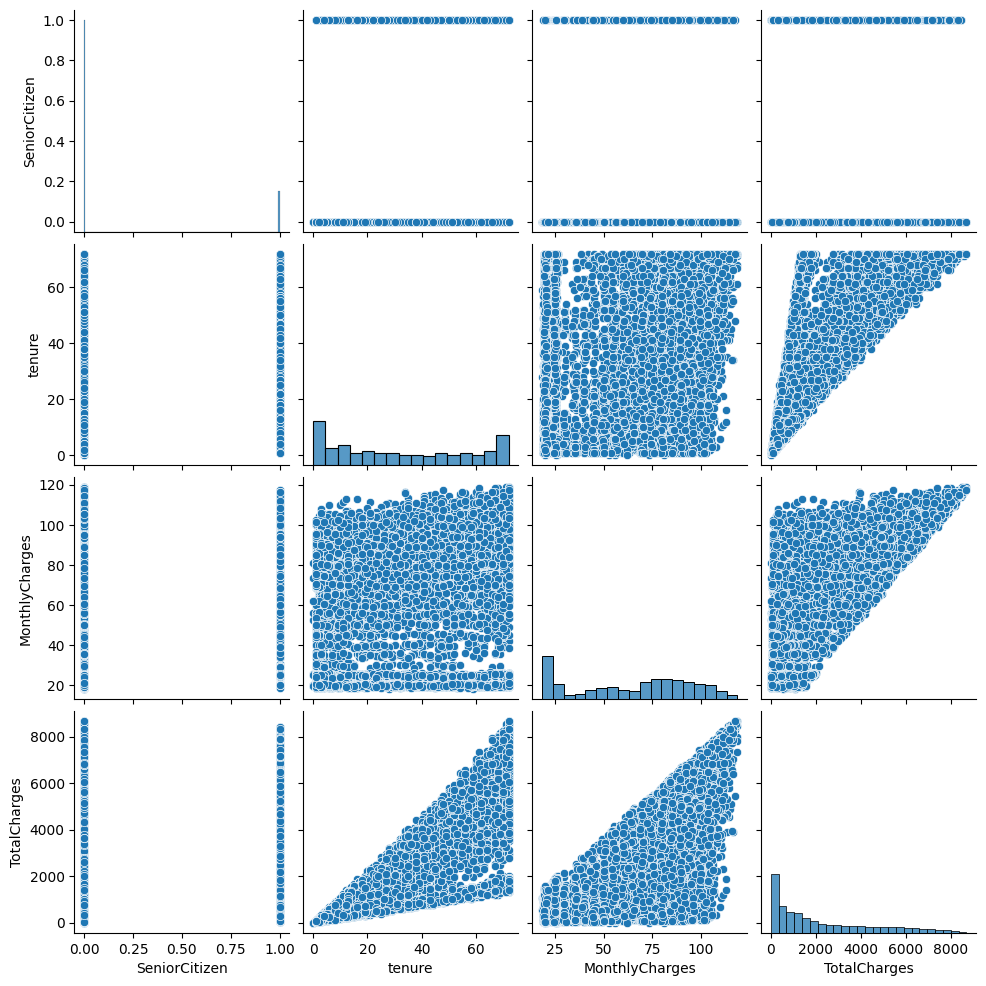

In [ ]:
sns.pairplot(df)

<Axes: xlabel='gender', ylabel='count'>

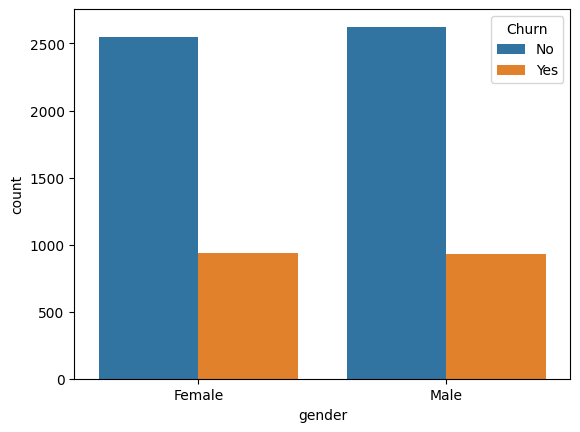

In [ ]:
sns.countplot(df,x='gender',hue='Churn')

<Axes: xlabel='Partner', ylabel='count'>

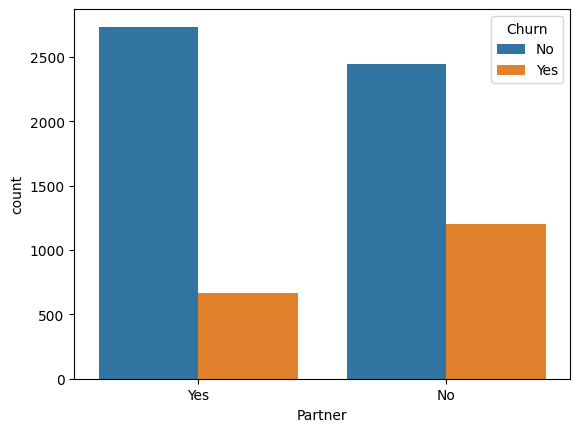

In [ ]:
sns.countplot(df,x='Partner',hue='Churn')

<Axes: xlabel='tenure', ylabel='Count'>

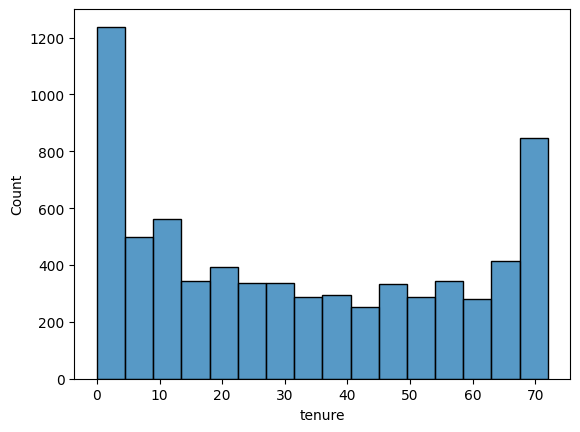

In [ ]:
sns.histplot(df,x='tenure')

<Axes: xlabel='MonthlyCharges', ylabel='Count'>

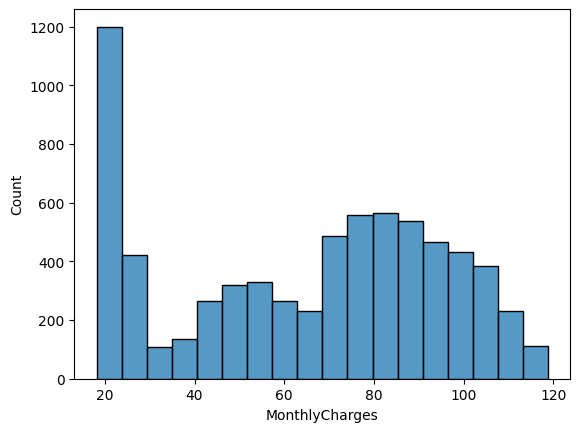

In [ ]:
sns.histplot(df,x='MonthlyCharges')

<Axes: xlabel='TotalCharges', ylabel='Count'>

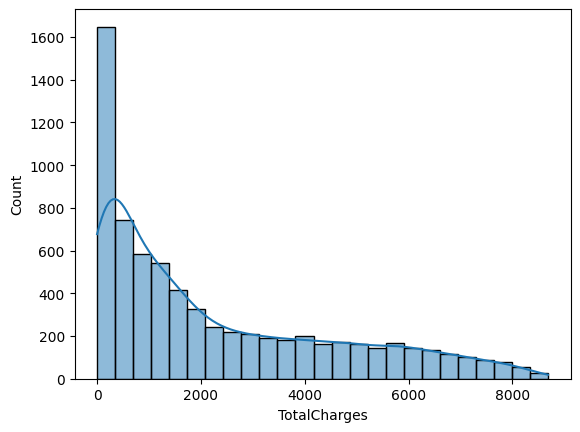

In [ ]:
sns.histplot(df,x='TotalCharges',kde=True)

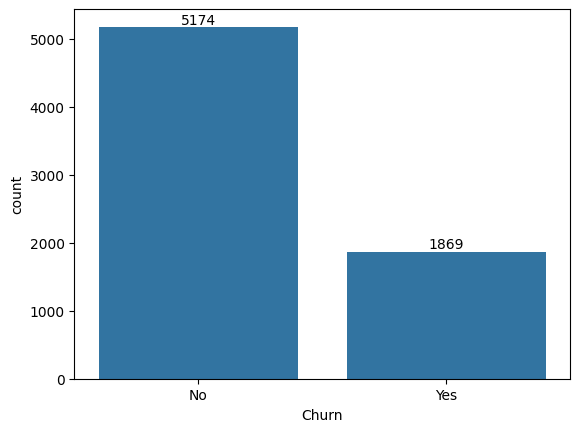

In [ ]:
ax = sns.countplot(df,x='Churn')

for i in ax.containers:
  ax.bar_label(i)

<Axes: xlabel='Contract', ylabel='count'>

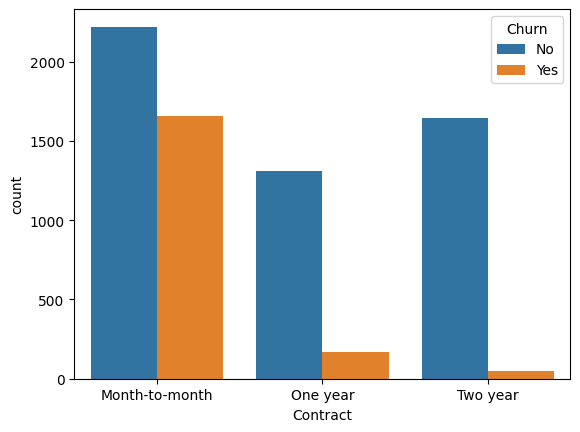

In [ ]:
sns.countplot(df,x='Contract',hue='Churn')

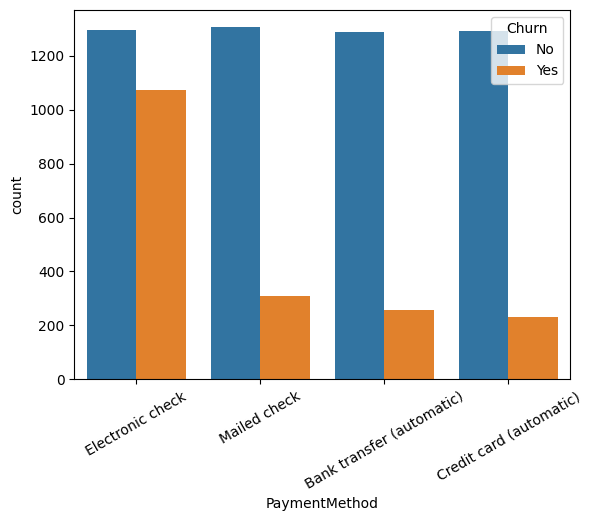

In [ ]:
sns.countplot(df,x='PaymentMethod',hue='Churn')
plt.xticks(rotation=30)
plt.show()

<Axes: xlabel='Churn', ylabel='MonthlyCharges'>

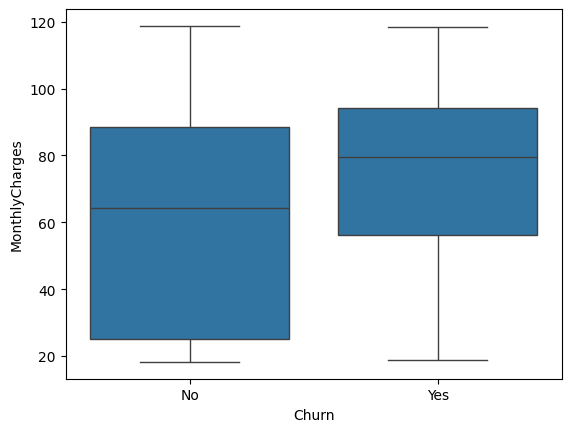

In [ ]:
sns.boxplot(df,x='Churn',y='MonthlyCharges')

<Axes: xlabel='Churn', ylabel='tenure'>

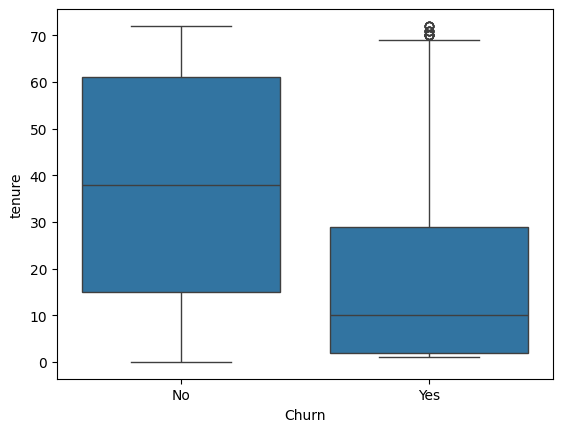

In [ ]:
sns.boxplot(df,x='Churn',y='tenure')

<Axes: xlabel='Churn', ylabel='TotalCharges'>

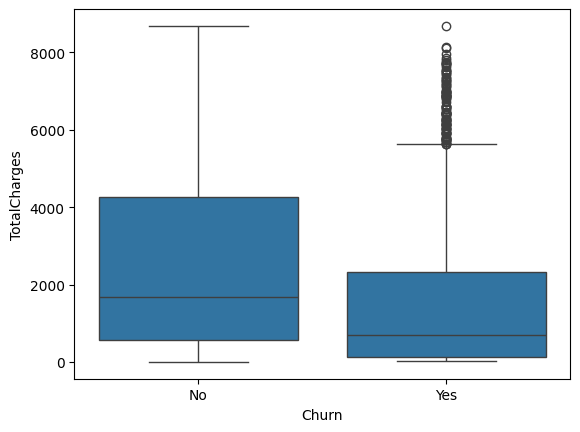

In [ ]:
sns.boxplot(df,x='Churn',y='TotalCharges')

<Axes: >

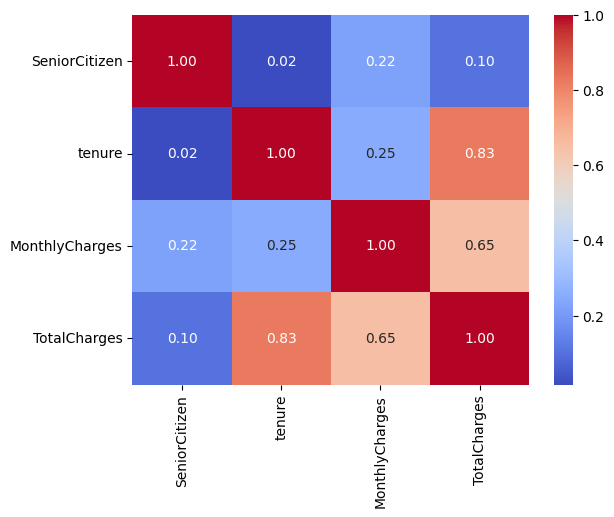

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm',fmt='.2f')

<Axes: xlabel='tenure', ylabel='TotalCharges'>

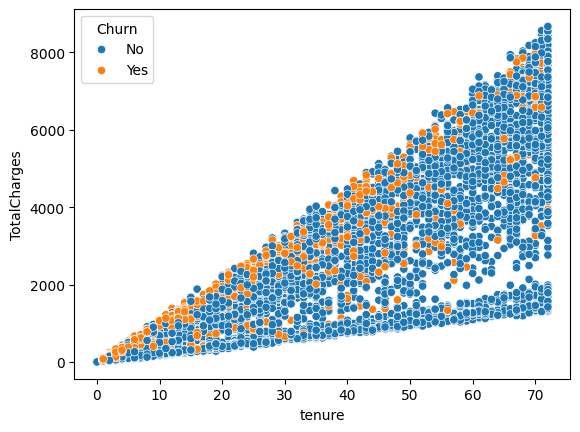

In [ ]:
sns.scatterplot(df,x='tenure',y='TotalCharges',hue='Churn')

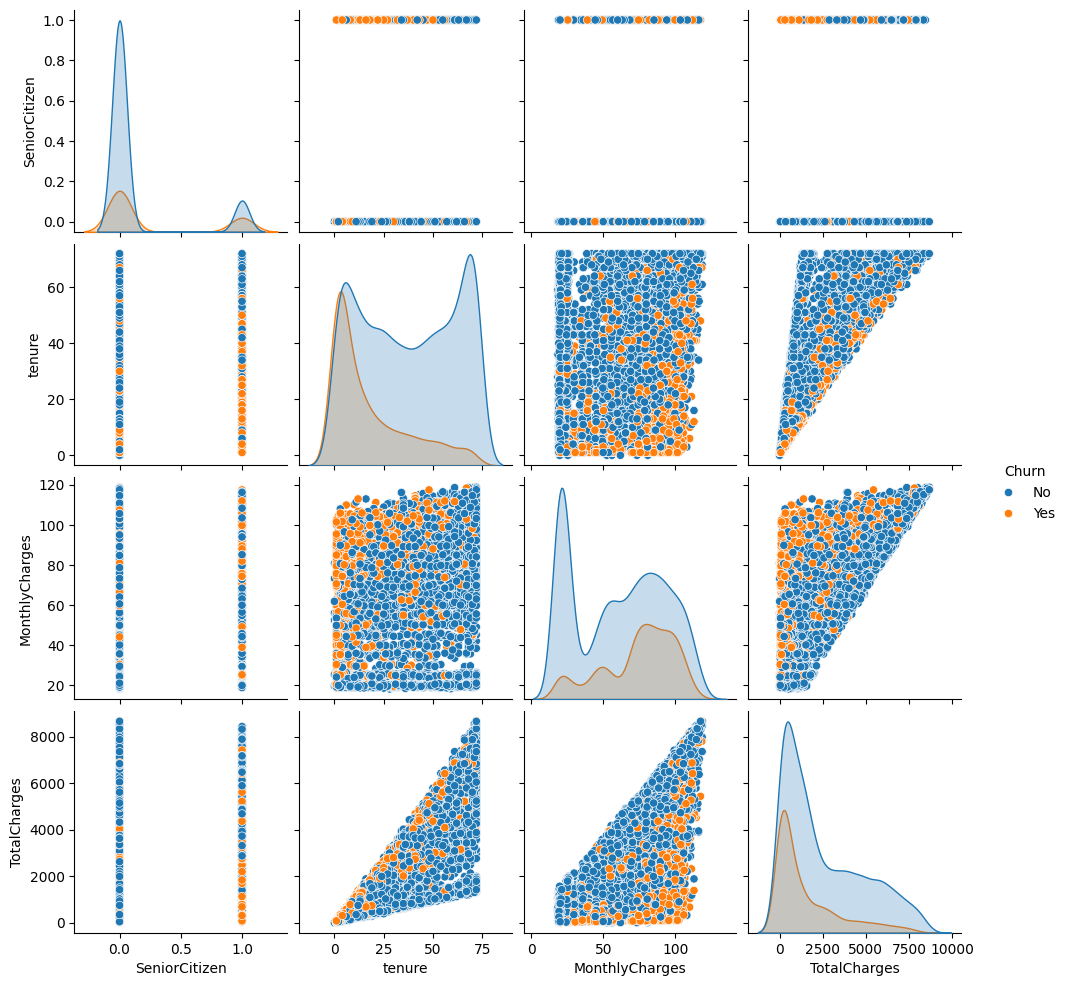

In [ ]:
sns.pairplot(df,hue='Churn')

In [ ]:
## data cleaing

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()].shape

(0, 21)

In [ ]:
df[df.duplicated(keep=False)].shape ## keep False is show to duplicate or orginal row and by defualt it is show only duplicate

(0, 21)

In [ ]:
## remove duplicate row's
df.drop_duplicates(inplace=True)

In [ ]:
df.skew(numeric_only=True)

,0
SeniorCitizen,1.833633
tenure,0.239540
MonthlyCharges,-0.220524
TotalCharges,0.963235


In [ ]:
df = df.drop(columns=['customerID'])

In [ ]:
## train test split

X = df.drop('Churn',axis=1)
y = df['Churn']

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
## create pipeline

In [ ]:
df.select_dtypes('object').columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='object')

In [ ]:
numerric_col = ['tenure','MonthlyCharges','TotalCharges']
cat_lable_col = ['gender', 'Partner', 'Dependents', 'PhoneService']
one_hot_col = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies',
       'PaperlessBilling', 'PaymentMethod']
ordinal_col = ['Contract']

In [ ]:
numerric_col_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

cat_lable_col_pipeline = Pipeline([
    ('label_encoder', OrdinalEncoder())
])

one_hot_col_pipeline = Pipeline([
    ('one_hot_encoder', OneHotEncoder(handle_unknown='ignore', drop='first'))
])

ordinal_col_pipeline = Pipeline([
    ('ordinal_encoder', OrdinalEncoder(categories=[['Month-to-month', 'One year', 'Two year']]))
])

In [ ]:
preprocessor = ColumnTransformer([
    ('numerric_col_pipeline',numerric_col_pipeline,numerric_col),
    ('cat_lable_col_pipeline',cat_lable_col_pipeline,cat_lable_col),
    ('one_hot_col_pipeline',one_hot_col_pipeline,one_hot_col),
    ('ordinal_col_pipeline',ordinal_col_pipeline,ordinal_col)
])

In [ ]:
# model pipeline

In [ ]:
models = {
    'DecisionTreeClassifier':DecisionTreeClassifier(random_state=42),
    'RandomForestClassifier':RandomForestClassifier(random_state=42,class_weight='balanced'),
    'XGBClassifier': XGBClassifier(random_state=42,scale_pos_weight=2.77), # = count(No) / count(Yes) ## provie to solve class unbalance
    'LGBMClassifier':LGBMClassifier(is_unbalance=True,random_state=42),
    'CatBoostClassifier':CatBoostClassifier(auto_class_weights='Balanced',verbose=False,random_state=42)
}

In [ ]:
# We also need to map our target variable 'y_train' and 'y_test' to binary (0 and 1)
# so that estimators like XGBClassifier can train on them successfully.

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

In [ ]:
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    cross_val_accuracy =  cross_val_score(pipe, X_train, y_train, cv=5,scoring='accuracy').mean()

    print(f'model name: {name}, accuracy: {accuracy_score(y_test, y_pred)} and cross val score: {cross_val_accuracy}')
    print('---'*50)
    print(classification_report(y_test, y_pred))
    print('---'*50)
    print(confusion_matrix(y_test, y_pred))
    print('---'*50)


model name: DecisionTreeClassifier, accuracy: 0.7423704755145494 and cross val score: 0.7252371548665802
------------------------------------------------------------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

           0       0.83      0.82      0.82      1035
           1       0.51      0.52      0.52       374

    accuracy                           0.74      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.74      0.74      1409

------------------------------------------------------------------------------------------------------------------------------------------------------
[[852 183]
 [180 194]]
------------------------------------------------------------------------------------------------------------------------------------------------------
model name: RandomForestClassifier, accuracy: 0.7828246983676366 and cross val score: 0.7894

In [ ]:
## Precision = out of all customers the model predicted "Yes", what percentage were really "Yes".

## Recall = out of all customers who really churned, what percentage did the model find.

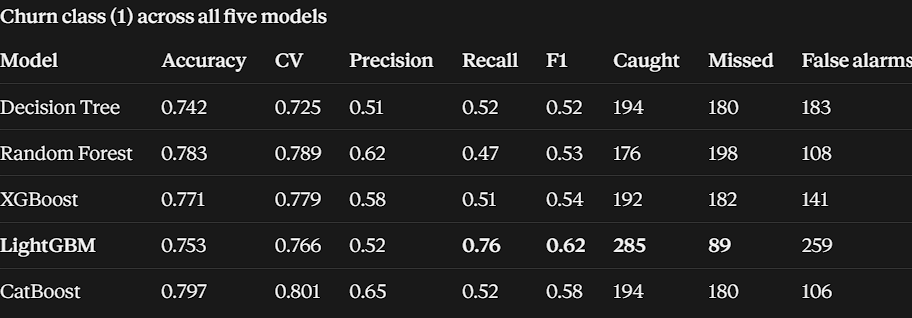

In [ ]:
## model pipeline

model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LGBMClassifier(is_unbalance=True,random_state=42))
])

In [ ]:
## hyper perameter

from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    'model__n_estimators': [100, 200, 300],
    'model__learning_rate': [0.01, 0.1, 0.2],
    'model__max_depth': [3, 4, 5],
    'model__min_child_samples': [5, 10, 15],
    'model__lambda_l2': [0.1, 0.5],
    'model__boosting_type': ['gbdt', 'dart','rf'],
    'model__reg_alpha': [0, 0.1],
    'model__reg_lambda': [0, 0.1],
}

In [ ]:
search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=5,
    scoring='f1',
    verbose=1,
    n_jobs=-1
)

In [ ]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000688 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265353 -> initscore=-1.018328
[LightGBM] [Info] Start training from score -1.018328
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No fur

RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerric_col_pipeline',
                                                                               Pipeline(steps=[('scaler',
                                                                                                StandardScaler())]),
                                                                               ['tenure',
                                                                                'MonthlyCharges',
                                                                                'TotalCharges']),
                                                                              ('cat_lable_col_pipeline',
                                                                               Pipeline(steps=[('label_encoder',
                                                                                                OrdinalEncoder())]),
                                                                               ['gender',
                                                                                'Partner',
                                                                                'Dependents',
                                                                                'PhoneService']),
                                                                              ('one_ho...
                                              LGBMClassifier(is_unbalance=True,
                                                             random_state=42))]),
                   n_jobs=-1,
                   param_distributions={'model__boosting_type': ['gbdt', 'dart',
                                                                 'rf'],
                                        'model__lambda_l2': [0.1, 0.5],
                                        'model__learning_rate': [0.01, 0.1,
                                                                 0.2],
                                        'model__max_depth': [3, 4, 5],
                                        'model__min_child_samples': [5, 10, 15],
                                        'model__n_estimators': [100, 200, 300],
                                        'model__reg_alpha': [0, 0.1],
                                        'model__reg_lambda': [0, 0.1]},
                   scoring='f1', verbose=1)

In [ ]:
search.best_params_

{'model__reg_lambda': 0.1,
 'model__reg_alpha': 0,
 'model__n_estimators': 200,
 'model__min_child_samples': 5,
 'model__max_depth': 5,
 'model__learning_rate': 0.01,
 'model__lambda_l2': 0.5,
 'model__boosting_type': 'gbdt'}

In [ ]:
search.best_score_

np.float64(0.6322313859933247)

In [ ]:
best_model = search.best_estimator_

In [ ]:
best_model.fit(X_train, y_train)

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000667 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265353 -> initscore=-1.018328
[LightGBM] [Info] Start training from score -1.018328
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerric_col_pipeline',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat_lable_col_pipeline',
                                                  Pipeline(steps=[('label_encoder',
                                                                   OrdinalEncoder())]),
                                                  ['gender', 'Partner',
                                                   'Dependents',
                                                   'PhoneService']),
                                                 ('one_hot_col_pipeline',
                                                  Pipeline(steps=[('...
                                                   'PaperlessBilling',
                                                   'PaymentMethod']),
                                                 ('ordinal_col_pipeline',
                                                  Pipeline(steps=[('ordinal_encoder',
                                                                   OrdinalEncoder(categories=[['Month-to-month',
                                                                                               'One '
                                                                                               'year',
                                                                                               'Two '
                                                                                               'year']]))]),
                                                  ['Contract'])])),
                ('model',
                 LGBMClassifier(is_unbalance=True, lambda_l2=0.5,
                                learning_rate=0.01, max_depth=5,
                                min_child_samples=5, n_estimators=200,
                                random_state=42, reg_alpha=0,
                                reg_lambda=0.1))])

In [ ]:
best_model.score(X_test,y_test)

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5


0.759403832505323

In [ ]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Extract the raw classifier from our tuned best_model pipeline
raw_lgbm_model = best_model.named_steps['model']

# Build the correct unified pipeline
corrected_pipe = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', raw_lgbm_model)
])

# Evaluate using Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(corrected_pipe, X_train, y_train, cv=cv, scoring='f1')
print("F1 Scores across folds:", scores)
print("Mean F1 Score:", scores.mean())

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Info] Number of positive: 3311, number of negative: 3311
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002717 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2037
[LightGBM] [Info] Number of data points in the train set: 6622, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [ ]:
# F1 Scores across folds: [0.61219196 0.60752688 0.60465116 0.61265823 0.64480874]

# Mean F1 Score: 0.6163673948048176

In [ ]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred))

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
              precision    recall  f1-score   support

           0       0.90      0.76      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



In [ ]:
confusion_matrix(y_test,y_pred)

array([[782, 253],
       [ 86, 288]])

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

res = cross_validate(best_model, X_train, y_train, cv=cv,
                     scoring=['f1','recall','precision','roc_auc'],
                     return_train_score=True)

for k in ['test_f1','test_recall','test_precision','test_roc_auc','train_f1']:
    print(k, res[k].mean().round(3))

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
[LightGBM] [Info] Number of positive: 1196, number of negative: 3311
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000324 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 635
[LightGBM] [Info] Number of data points in the train set: 4507, number of used features: 28
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.265365 -> initscore=-1.018268
[LightGBM] [Info] Start training from score -1.018268
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [W

In [ ]:
y_prob_test = best_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_prob_test >= 0.5).astype(int)
print(classification_report(y_test, y_pred_final))

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
              precision    recall  f1-score   support

           0       0.90      0.76      0.82      1035
           1       0.53      0.77      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.76      0.77      1409



In [ ]:
## thresold cross val

from sklearn.metrics import precision_score, recall_score, f1_score
for t in [0.3, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7]:
    p = (y_prob_test >= t).astype(int)
    print(t, round(precision_score(y_test, p), 2),
          round(recall_score(y_test, p), 2),
          round(f1_score(y_test, p), 2))

0.3 0.42 0.93 0.58
0.4 0.49 0.84 0.62
0.45 0.52 0.81 0.63
0.5 0.53 0.77 0.63
0.55 0.57 0.72 0.63
0.6 0.59 0.65 0.62
0.7 0.69 0.41 0.51


In [ ]:
from sklearn.metrics import roc_curve

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob_test)

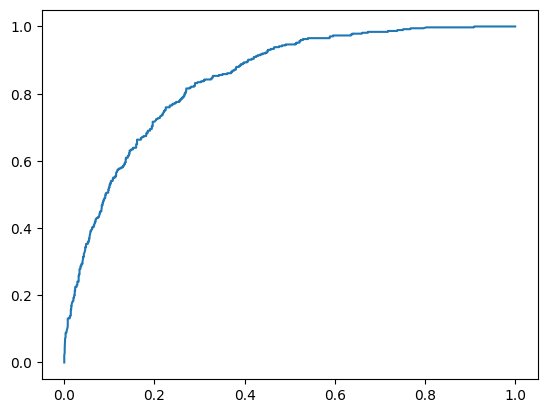

In [ ]:
plt.plot(fpr, tpr)

Text(0.5, 1.0, 'ROC Curve')

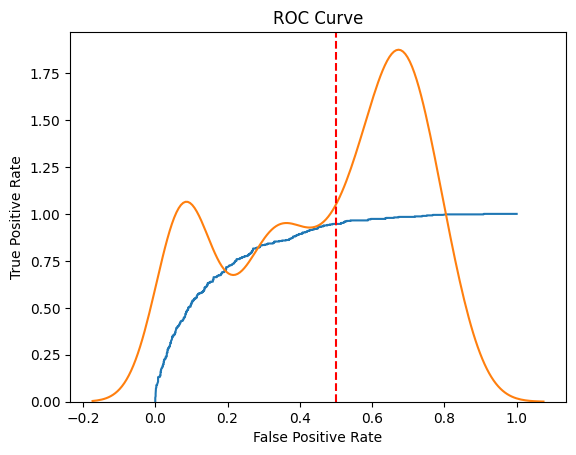

In [ ]:
plt.plot(fpr, tpr)
sns.kdeplot(thresholds, label='Thresholds')
plt.axvline(0.5, color='red', linestyle='--', label='Best Threshold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

In [ ]:
import joblib
joblib.dump({'model': best_model, 'threshold': 0.5}, 'churn_model.pkl')

['churn_model.pkl']

In [ ]:
X_test.index

Index([ 437, 2280, 2235, 4460, 3761, 5748, 3568, 2976, 5928, 1639,
       ...
       1421, 4765,  153, 4708, 3701, 5143, 4439, 3857, 4758, 5613],
      dtype='int64', length=1409)

In [ ]:
df.iloc[X_test.index]['Churn'].sample()

,Churn
5003,Yes


In [ ]:
X_test.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
437,Male,0,Yes,Yes,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),114.05,8468.20
2280,Female,1,No,No,8,Yes,Yes,Fiber optic,No,No,No,Yes,Yes,Yes,Month-to-month,Yes,Credit card (automatic),100.15,908.55
2235,Female,0,Yes,Yes,41,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,No,One year,Yes,Credit card (automatic),78.35,3211.20
4460,Male,0,Yes,No,18,Yes,No,Fiber optic,No,No,Yes,Yes,No,No,Month-to-month,No,Electronic check,78.20,1468.75
3761,Female,0,Yes,No,72,Yes,Yes,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),82.65,5919.35


In [ ]:
X_test.loc[[3694]].to_dict()

{'gender': {3694: 'Female'},
 'SeniorCitizen': {3694: 0},
 'Partner': {3694: 'Yes'},
 'Dependents': {3694: 'Yes'},
 'tenure': {3694: 67},
 'PhoneService': {3694: 'Yes'},
 'MultipleLines': {3694: 'Yes'},
 'InternetService': {3694: 'Fiber optic'},
 'OnlineSecurity': {3694: 'Yes'},
 'OnlineBackup': {3694: 'No'},
 'DeviceProtection': {3694: 'Yes'},
 'TechSupport': {3694: 'Yes'},
 'StreamingTV': {3694: 'Yes'},
 'StreamingMovies': {3694: 'Yes'},
 'Contract': {3694: 'Two year'},
 'PaperlessBilling': {3694: 'Yes'},
 'PaymentMethod': {3694: 'Credit card (automatic)'},
 'MonthlyCharges': {3694: 108.75},
 'TotalCharges': {3694: 7156.2}}

In [ ]:
X_test.loc[3694].values

array(['Female', np.int64(0), 'Yes', 'Yes', np.int64(67), 'Yes', 'Yes',
       'Fiber optic', 'Yes', 'No', 'Yes', 'Yes', 'Yes', 'Yes', 'Two year',
       'Yes', 'Credit card (automatic)', np.float64(108.75),
       np.float64(7156.2)], dtype=object)

In [ ]:
import joblib
import pandas as pd

##
no = 5003

# Load the dictionary
saved_data = joblib.load('churn_model.pkl')

# Extract the actual trained pipeline
pipeline = saved_data['model']

# Correct way: Pass the slice as a DataFrame directly instead of converting to a dict
row_df = X_test.loc[[no]]
prediction = pipeline.predict(row_df)

print("Predicted class:", prediction[0])
print("Original Target:", df.loc[no, 'Churn'])

[LightGBM] [Warning] lambda_l2 is set=0.5, reg_lambda=0.1 will be ignored. Current value: lambda_l2=0.5
Predicted class: 1
Original Target: Yes
